# teste de códigos para a testa

In [211]:
import os
import urllib.request

MODEL_PATH = "face_landmarker.task"
MODEL_URL = "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task"

if not os.path.exists(MODEL_PATH):
    print("Downloading face_landmarker.task model...")
    urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)
    print("Download complete!")

In [212]:
pip install opencv-python mediapipe numpy

In [213]:
#visualização da máscara; o ficheiro de input tem de ter o nome input_person.mp4
'''
o input tem de ser um vídeo no formato .mp4
deteta as sobrancelhas usando face landmarks e depois deteta a hairline ao detetar a edge onde acaba a cor de pele da pessoa.
ajusta-se automáticamente a varios tamanhos de testa e a cores de pele
'''


import os
import urllib.request
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

#required model
def download_model_if_missing(model_path="face_landmarker.task"):
    model_url = "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task"
    if not os.path.exists(model_path):
        print("Downloading face_landmarker.task model...")
        urllib.request.urlretrieve(model_url, model_path)
        print("Download complete!")


def get_calibrated_skin_mask(hsv_frame, sample_point, radius=5):
    """
    Samples the subject's actual skin colour around a sample_point to build an adaptive skin colour mask for the current frame.
    """
    x, y = sample_point
    h, w = hsv_frame.shape[:2]

    x1, x2 = max(0, x - radius), min(w, x + radius)
    y1, y2 = max(0, y - radius), min(h, y + radius)

    sample_roi = hsv_frame[y1:y2, x1:x2]
    if sample_roi.size == 0:
        # Fallback to general skin range if sampling fails
        return cv2.inRange(hsv_frame, np.array([0, 20, 70]), np.array([25, 255, 255]))

    # Calculate mean Hue, Saturation, Value
    mean_hsv = np.mean(sample_roi, axis=(0, 1))

    # Adaptive tolerance ranges around sampled skin tone
    lower_skin = np.array([max(0, mean_hsv[0] - 15), max(20, mean_hsv[1] - 40), max(40, mean_hsv[2] - 60)], dtype=np.uint8)
    upper_skin = np.array([min(180, mean_hsv[0] + 15), min(255, mean_hsv[1] + 40), min(255, mean_hsv[2] + 60)], dtype=np.uint8)

    return cv2.inRange(hsv_frame, lower_skin, upper_skin)

#Nota: testar isto em videos de pessoas muito loiras
def find_hairline_above_mesh(hsv_frame, skin_mask, start_x, start_y, max_search_up):
    """
    Scans strictly UPWARDS starting FROM start_y (which is already above eyebrows)
    towards the hairline, preventing any eyebrow interference.
    """
    h_frame, w_frame = hsv_frame.shape[:2]

    strip_w = 6
    x1 = max(0, int(start_x - strip_w))
    x2 = min(w_frame, int(start_x + strip_w))

    y_start = int(start_y)
    y_end = max(0, int(start_y - max_search_up))

    if y_start <= y_end or x2 <= x1:
        return y_start

    # Extract skin mask strip starting at mesh and going upwards
    skin_strip = skin_mask[y_end:y_start, x1:x2]
    if skin_strip.size == 0:
        return y_start

    skin_profile = np.mean(skin_strip, axis=1)  # Top to bottom in strip coordinates

    # Scan from start_y UPWARDS (bottom of strip to top of strip)
    for idx in range(len(skin_profile) - 1, -1, -1):
        if skin_profile[idx] < 100:  # First non-skin pixel hit = Hairline root
            return y_end + idx

    # If no hair hit within search distance, return highest scanned point
    return y_end

def create_forehead_overlay_stable(video_path: str, output_path: str, model_path: str = "face_landmarker.task"):
    download_model_if_missing(model_path)

    base_options = python.BaseOptions(model_asset_path=model_path)
    options = vision.FaceLandmarkerOptions(
        base_options=base_options,
        running_mode=vision.RunningMode.VIDEO,
        num_faces=1
    )

    detector = vision.FaceLandmarker.create_from_options(options)

    # face landmarks:
    #eyebrow line
    BROW_LINE = [70, 63, 105, 66, 107, 336, 296, 334, 293, 300]
    #upper forehead (extended upward depending on the person)
    UPPER_MESH_POINTS = [103, 67, 109, 10, 338, 297, 332]

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print(f"Error: Could not open video {video_path}")
        return

    #video information
    fps = int(cap.get(cv2.CAP_PROP_FPS)) or 30
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

    frame_timestamp_ms = 0
    frame_duration_ms = int(1000 / fps)

    # Temporal smoothing buffer for upper hairline points
    prev_upper_pts = None
    smooth_factor = 0.6  # 0.6 current frame, 0.4 historical memory

    print("Processing video with stable hairline tracking...")

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb_frame)

        detection_result = detector.detect_for_video(mp_image, frame_timestamp_ms)
        frame_timestamp_ms += frame_duration_ms

        annotated_frame = frame.copy()

        if detection_result.face_landmarks:
            landmarks = detection_result.face_landmarks[0]

            # 1. Calibrate skin color using mid-forehead landmark (landmark #10 or #151)
            sample_x = int(landmarks[151].x * width)
            sample_y = int(landmarks[151].y * height)

            hsv_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
            skin_mask = get_calibrated_skin_mask(hsv_frame, (sample_x, sample_y))

            # 2. Scale search height based on face size
            brow_center_y = landmarks[9].y * height
            nose_y = landmarks[1].y * height
            face_height_scale = abs(nose_y - brow_center_y)
            max_search_up = face_height_scale * 1.0

            poly_points = []

            # Add lower boundary (Eyebrow line)
            for idx in BROW_LINE:
                lm = landmarks[idx]
                poly_points.append([int(lm.x * width), int(lm.y * height)])

            # Detect upper hairline points starting ABOVE eyebrows
            raw_upper_pts = []
            for idx in UPPER_MESH_POINTS:
                lm = landmarks[idx]
                lm_x = int(lm.x * width)
                lm_y = int(lm.y * height)

                auto_y = find_hairline_above_mesh(
                    hsv_frame=hsv_frame,
                    skin_mask=skin_mask,
                    start_x=lm_x,
                    start_y=lm_y,
                    max_search_up=max_search_up
                )
                raw_upper_pts.append([lm_x, auto_y])

            # 3. Apply Temporal Smoothing (prevents single-frame triangle glitches)
            raw_upper_pts = np.array(raw_upper_pts, dtype=np.float32)
            if prev_upper_pts is None:
                smooth_upper_pts = raw_upper_pts
            else:
                smooth_upper_pts = (smooth_factor * raw_upper_pts) + ((1 - smooth_factor) * prev_upper_pts)

            prev_upper_pts = smooth_upper_pts
            upper_pts_int = smooth_upper_pts.astype(np.int32).tolist()

            # Construct complete closed forehead polygon
            poly_points.extend(reversed(upper_pts_int))
            pts = np.array([poly_points], dtype=np.int32)

            # Draw smooth transparent mask
            overlay = annotated_frame.copy()
            cv2.fillPoly(overlay, pts, color=(0, 255, 0))

            alpha = 0.4
            cv2.addWeighted(overlay, alpha, annotated_frame, 1 - alpha, 0, annotated_frame)
            cv2.polylines(annotated_frame, pts, isClosed=True, color=(0, 255, 0), thickness=2)

        out.write(annotated_frame)

    cap.release()
    out.release()
    detector.close()
    print(f"Finished! Saved stable overlay video to: {output_path}")

if __name__ == "__main__":
    create_forehead_overlay_stable("input_person.mp4", "forehead_stable.mp4")

Processing video with stable hairline tracking...
Finished! Saved stable overlay video to: forehead_stable.mp4


In [214]:
#teste da extração dos canais rgb; o ficheiro de input tem de ter o nome input_person.mp4
'''
este código extrai a média de cada canal rgb da mascara do código acima
'''

import os
import urllib.request
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

def download_model_if_missing(model_path="face_landmarker.task"):
    model_url = "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task"
    if not os.path.exists(model_path):
        print("Downloading face_landmarker.task model...")
        urllib.request.urlretrieve(model_url, model_path)
        print("Download complete!")

def get_calibrated_skin_mask(hsv_frame, sample_point, radius=5):
    x, y = sample_point
    h, w = hsv_frame.shape[:2]
    x1, x2 = max(0, x - radius), min(w, x + radius)
    y1, y2 = max(0, y - radius), min(h, y + radius)

    sample_roi = hsv_frame[y1:y2, x1:x2]
    if sample_roi.size == 0:
        return cv2.inRange(hsv_frame, np.array([0, 20, 70]), np.array([25, 255, 255]))

    mean_hsv = np.mean(sample_roi, axis=(0, 1))
    lower_skin = np.array([max(0, mean_hsv[0] - 15), max(20, mean_hsv[1] - 40), max(40, mean_hsv[2] - 60)], dtype=np.uint8)
    upper_skin = np.array([min(180, mean_hsv[0] + 15), min(255, mean_hsv[1] + 40), min(255, mean_hsv[2] + 60)], dtype=np.uint8)

    return cv2.inRange(hsv_frame, lower_skin, upper_skin)

def find_hairline_above_mesh(hsv_frame, skin_mask, start_x, start_y, max_search_up):
    h_frame, w_frame = hsv_frame.shape[:2]
    strip_w = 6
    x1 = max(0, int(start_x - strip_w))
    x2 = min(w_frame, int(start_x + strip_w))

    y_start = int(start_y)
    y_end = max(0, int(start_y - max_search_up))

    if y_start <= y_end or x2 <= x1:
        return y_start

    skin_strip = skin_mask[y_end:y_start, x1:x2]
    if skin_strip.size == 0:
        return y_start

    skin_profile = np.mean(skin_strip, axis=1)

    for idx in range(len(skin_profile) - 1, -1, -1):
        if skin_profile[idx] < 100:
            return y_end + idx

    return y_end

def extract_forehead_rgb_signals(video_path: str, model_path: str = "face_landmarker.task"):
    """
    Tracks the forehead mask and calculates average R, G, and B channel values for each frame.
    Returns:
        r_means, g_means, b_means: 1D numpy arrays containing mean values per frame.
    """
    download_model_if_missing(model_path)

    base_options = python.BaseOptions(model_asset_path=model_path)
    options = vision.FaceLandmarkerOptions(
        base_options=base_options,
        running_mode=vision.RunningMode.VIDEO,
        num_faces=1
    )

    detector = vision.FaceLandmarker.create_from_options(options)

    BROW_LINE = [70, 63, 105, 66, 107, 336, 296, 334, 293, 300]
    UPPER_MESH_POINTS = [103, 67, 109, 10, 338, 297, 332]

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print(f"Error: Could not open video {video_path}")
        return None, None, None

    fps = int(cap.get(cv2.CAP_PROP_FPS)) or 30
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    frame_timestamp_ms = 0
    frame_duration_ms = int(1000 / fps)

    prev_upper_pts = None
    smooth_factor = 0.6

    # Output vectors
    r_means, g_means, b_means = [], [], []

    print("Extracting RGB mean values from forehead region...")

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb_frame)

        detection_result = detector.detect_for_video(mp_image, frame_timestamp_ms)
        frame_timestamp_ms += frame_duration_ms

        if detection_result.face_landmarks:
            landmarks = detection_result.face_landmarks[0]

            # Skin color calibration
            sample_x = int(landmarks[151].x * width)
            sample_y = int(landmarks[151].y * height)
            hsv_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
            skin_mask = get_calibrated_skin_mask(hsv_frame, (sample_x, sample_y))

            brow_center_y = landmarks[9].y * height
            nose_y = landmarks[1].y * height
            face_height_scale = abs(nose_y - brow_center_y)
            max_search_up = face_height_scale * 1.0

            poly_points = []
            for idx in BROW_LINE:
                lm = landmarks[idx]
                poly_points.append([int(lm.x * width), int(lm.y * height)])

            raw_upper_pts = []
            for idx in UPPER_MESH_POINTS:
                lm = landmarks[idx]
                lm_x = int(lm.x * width)
                lm_y = int(lm.y * height)

                auto_y = find_hairline_above_mesh(hsv_frame, skin_mask, lm_x, lm_y, max_search_up)
                raw_upper_pts.append([lm_x, auto_y])

            # Temporal smoothing
            raw_upper_pts = np.array(raw_upper_pts, dtype=np.float32)
            if prev_upper_pts is None:
                smooth_upper_pts = raw_upper_pts
            else:
                smooth_upper_pts = (smooth_factor * raw_upper_pts) + ((1 - smooth_factor) * prev_upper_pts)

            prev_upper_pts = smooth_upper_pts
            upper_pts_int = smooth_upper_pts.astype(np.int32).tolist()

            poly_points.extend(reversed(upper_pts_int))
            pts = np.array([poly_points], dtype=np.int32)

            # Create binary mask (255 inside forehead polygon, 0 outside)
            forehead_mask = np.zeros((height, width), dtype=np.uint8)
            cv2.fillPoly(forehead_mask, pts, 255)

            # Calculate mean RGB values strictly within the masked region
            # OpenCV frames are BGR by default -> convert to RGB channel ordering
            b_mean, g_mean, r_mean, _ = cv2.mean(frame, mask=forehead_mask)

            r_means.append(r_mean)
            g_means.append(g_mean)
            b_means.append(b_mean)
        else:
            # Append NaN or 0 if no face is detected in the frame
            r_means.append(np.nan)
            g_means.append(np.nan)
            b_means.append(np.nan)

    cap.release()
    detector.close()

    print(f"Extraction complete! Extracted {len(r_means)} frame measurements.")
    return np.array(r_means), np.array(g_means), np.array(b_means)

if __name__ == "__main__":
    input_video = "input_person.mp4"

    # Run signal extraction
    r_channel, g_channel, b_channel = extract_forehead_rgb_signals(input_video)

    print("R Channel Vector shape:", r_channel.shape)
    print("First 5 Red channel mean values:", r_channel[:5])
    print("First 5 Green channel mean values:", g_channel[:5])
    print("First 5 Blue channel mean values:", b_channel[:5])

Extracting RGB mean values from forehead region...
Extraction complete! Extracted 641 frame measurements.
R Channel Vector shape: (641,)
First 5 Red channel mean values: [119.95962466 117.20302997 117.50775194 117.91177878 118.17169112]
First 5 Green channel mean values: [92.98021448 89.98528454 91.04164182 91.5071285  92.05551128]
First 5 Blue channel mean values: [90.04847185 87.86213076 88.87875174 89.08472873 88.94467626]


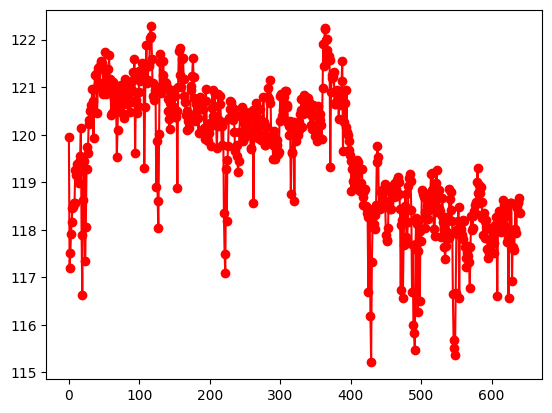

In [215]:
import matplotlib.pyplot as plt
plt.plot(r_channel, linestyle='-', marker='o', color="red")

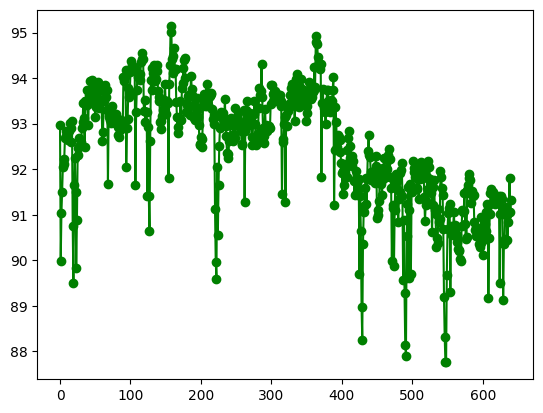

In [216]:
import matplotlib.pyplot as plt
plt.plot(g_channel, linestyle='-', marker='o', color="green")

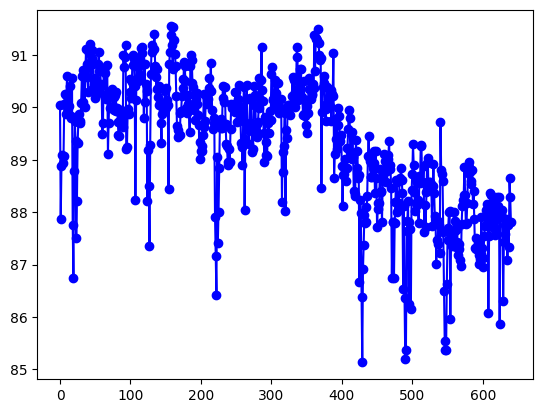

In [217]:
import matplotlib.pyplot as plt
plt.plot(b_channel, linestyle='-', marker='o', color="blue")

# código final limpo para a testa

In [218]:
'''
input any video of a person in .mp4 and choose the rgb channel you want to extract
output is the mean of each frame of the rgb channel after masking only the forehead of the person
'''

import os
import urllib.request
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

def download_model_if_missing(model_path="face_landmarker.task"):
    model_url = "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task"
    if not os.path.exists(model_path):
        print("Downloading face_landmarker.task model...")
        urllib.request.urlretrieve(model_url, model_path)
        print("Download complete!")

#sample skin colour
def get_calibrated_skin_mask(hsv_frame, sample_point, radius=5):
    x, y = sample_point
    h, w = hsv_frame.shape[:2]
    x1, x2 = max(0, x - radius), min(w, x + radius)
    y1, y2 = max(0, y - radius), min(h, y + radius)

    sample_roi = hsv_frame[y1:y2, x1:x2]
    if sample_roi.size == 0:
        return cv2.inRange(hsv_frame, np.array([0, 20, 70]), np.array([25, 255, 255]))

    mean_hsv = np.mean(sample_roi, axis=(0, 1))
    lower_skin = np.array([max(0, mean_hsv[0] - 15), max(20, mean_hsv[1] - 40), max(40, mean_hsv[2] - 60)], dtype=np.uint8)
    upper_skin = np.array([min(180, mean_hsv[0] + 15), min(255, mean_hsv[1] + 40), min(255, mean_hsv[2] + 60)], dtype=np.uint8)

    return cv2.inRange(hsv_frame, lower_skin, upper_skin)

#find where the forehead ends
def find_hairline_above_mesh(hsv_frame, skin_mask, start_x, start_y, max_search_up):
    h_frame, w_frame = hsv_frame.shape[:2]
    strip_w = 6
    x1 = max(0, int(start_x - strip_w))
    x2 = min(w_frame, int(start_x + strip_w))

    y_start = int(start_y)
    y_end = max(0, int(start_y - max_search_up))

    if y_start <= y_end or x2 <= x1:
        return y_start

    skin_strip = skin_mask[y_end:y_start, x1:x2]
    if skin_strip.size == 0:
        return y_start

    skin_profile = np.mean(skin_strip, axis=1)

    for idx in range(len(skin_profile) - 1, -1, -1):
        if skin_profile[idx] < 100:
            return y_end + idx

    return y_end


def extract_forehead_rgb_signals(video_path: str, model_path: str = "face_landmarker.task"):
    """
    Tracks the forehead mask and calculates average R, G, and B channel values for each frame.
    Returns: r_means, g_means, b_means: 1D numpy arrays containing mean values per frame.
    """
    #run the model on video of 1 face
    download_model_if_missing(model_path)
    base_options = python.BaseOptions(model_asset_path=model_path)
    options = vision.FaceLandmarkerOptions(base_options=base_options, running_mode=vision.RunningMode.VIDEO, num_faces=1)
    detector = vision.FaceLandmarker.create_from_options(options)

    #face landmarks
    BROW_LINE = [70, 63, 105, 66, 107, 336, 296, 334, 293, 300]
    UPPER_MESH_POINTS = [103, 67, 109, 10, 338, 297, 332] #horizontal line in the middle of the forehead

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print(f"Error: Could not open video {video_path}")
        return None, None, None

    #get information about the video file
    fps = int(cap.get(cv2.CAP_PROP_FPS)) or 30
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    frame_timestamp_ms = 0
    frame_duration_ms = int(1000 / fps)
    time = []

    prev_upper_pts = None
    smooth_factor = 0.6

    # Output vectors
    r_means, g_means, b_means = [], [], []


    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb_frame)

        detection_result = detector.detect_for_video(mp_image, frame_timestamp_ms)
        frame_timestamp_ms += frame_duration_ms
        time.append(frame_timestamp_ms)

        if detection_result.face_landmarks:
            landmarks = detection_result.face_landmarks[0]

            # Skin color calibration
            #sample_x and sample_y correspnd to the middle of the frehead
            sample_x = int(landmarks[151].x * width)
            sample_y = int(landmarks[151].y * height)
            hsv_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
            skin_mask = get_calibrated_skin_mask(hsv_frame, (sample_x, sample_y))

            #if a person is bald we need to establish when to stop searching for a hairline
            #by adjusting the coefficient of max_search_up we can adjust that
            brow_center_y = landmarks[9].y * height
            nose_y = landmarks[1].y * height
            face_height_scale = abs(nose_y - brow_center_y)
            max_search_up = face_height_scale * 1.0

            #determine eyebrow boundary
            poly_points = []
            for idx in BROW_LINE:
                lm = landmarks[idx]
                poly_points.append([int(lm.x * width), int(lm.y * height)])

            #determine hairline boundary
            raw_upper_pts = []
            for idx in UPPER_MESH_POINTS:
                lm = landmarks[idx]
                lm_x = int(lm.x * width)
                lm_y = int(lm.y * height)

                auto_y = find_hairline_above_mesh(hsv_frame, skin_mask, lm_x, lm_y, max_search_up)
                raw_upper_pts.append([lm_x, auto_y])

            # Temporal smoothing (to prevent glitches when the face moves)
            raw_upper_pts = np.array(raw_upper_pts, dtype=np.float32)
            if prev_upper_pts is None:
                smooth_upper_pts = raw_upper_pts
            else:
                #exponntial moving average: position of the point is based on the position of the current frame and the previous frame
                #smooth factor can be adjusted: currently it's 0.6
                smooth_upper_pts = (smooth_factor * raw_upper_pts) + ((1 - smooth_factor) * prev_upper_pts)

            prev_upper_pts = smooth_upper_pts
            upper_pts_int = smooth_upper_pts.astype(np.int32).tolist()

            #create a polygon of the forehead
            poly_points.extend(reversed(upper_pts_int))
            pts = np.array([poly_points], dtype=np.int32)

            # Create binary mask (255 inside forehead polygon, 0 outside)
            forehead_mask = np.zeros((height, width), dtype=np.uint8)
            cv2.fillPoly(forehead_mask, pts, 255)

            # Calculate mean RGB values strictly within the masked region
            # OpenCV frames are BGR by default, we need to convert to RGB
            b_mean, g_mean, r_mean, _ = cv2.mean(frame, mask=forehead_mask)

            r_means.append(r_mean)
            g_means.append(g_mean)
            b_means.append(b_mean)
        else:
            # Append 0 if no face is detected in the frame
            r_means.append(0)
            g_means.append(0)
            b_means.append(0)

    cap.release()
    detector.close()

    print(f"Extraction complete! Extracted {len(r_means)} frame measurements.")
    return np.array(r_means), np.array(g_means), np.array(b_means), fps

def signal_extraction_main_forehead(input_video, input_channel):
  '''
  input_video is a video file .mp4
  input_chanel is either:
  'r' for red channel,'g' for green channel or 'b' for blue channel
  '''

  # Run signal extraction
  r_channel, g_channel, b_channel, fps = extract_forehead_rgb_signals(input_video)
  if input_channel == 'r':
      return r_channel, fps
  elif input_channel == 'g':
      return g_channel, fps
  elif input_channel == 'b':
      return b_channel, fps
  else:
      print('invalid input channel')

Extraction complete! Extracted 641 frame measurements.


Text(0.5, 1.0, 'Green Channel Forehead')

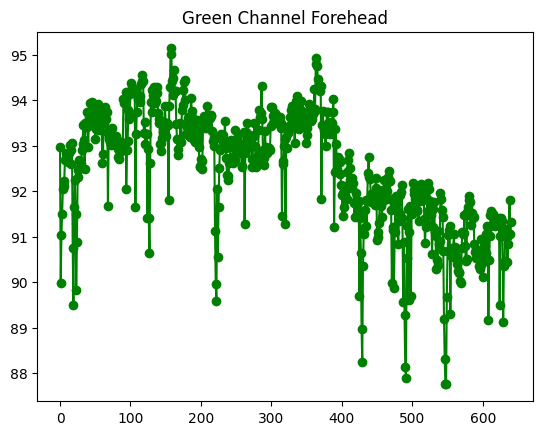

In [219]:
#exemplo de utilização
import matplotlib.pyplot as plt
green_forehead, fps = signal_extraction_main_forehead('/content/input_person.mp4', 'g')
plt.plot(green_forehead, linestyle='-', marker='o', color="green")
plt.title("Green Channel Forehead")


# testes do código para as bochechas

In [220]:
#visualização da máscara; o ficheiro de input tem de ter o nome input_person.mp4
import os
import urllib.request
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

def download_model_if_missing(model_path="face_landmarker.task"):
    model_url = "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task"
    if not os.path.exists(model_path):
        print("Downloading face_landmarker.task model...")
        urllib.request.urlretrieve(model_url, model_path)
        print("Download complete!")

def create_upper_cheeks_overlay(video_path: str, output_path: str, model_path: str = "face_landmarker.task"):
    download_model_if_missing(model_path)

    base_options = python.BaseOptions(model_asset_path=model_path)
    options = vision.FaceLandmarkerOptions(
        base_options=base_options,
        running_mode=vision.RunningMode.VIDEO,
        num_faces=1
    )

    detector = vision.FaceLandmarker.create_from_options(options)

    # Upper Cheek Landmarks (strictly ABOVE mouth line, below eyes, staying on upper skin)
    LEFT_UPPER_CHEEK = [117, 118, 101, 36, 205, 207, 187, 147, 123]
    RIGHT_UPPER_CHEEK = [346, 347, 330, 266, 425, 427, 411, 376, 352]

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print(f"Error: Could not open video {video_path}")
        return

    fps = int(cap.get(cv2.CAP_PROP_FPS)) or 30
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

    frame_timestamp_ms = 0
    frame_duration_ms = int(1000 / fps)

    # Buffers for temporal smoothing
    prev_left_pts = None
    prev_right_pts = None
    smooth_factor = 0.6

    print("Processing video with upper cheek masks (beard-free & no triangles)...")

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb_frame)

        detection_result = detector.detect_for_video(mp_image, frame_timestamp_ms)
        frame_timestamp_ms += frame_duration_ms

        annotated_frame = frame.copy()

        if detection_result.face_landmarks:
            landmarks = detection_result.face_landmarks[0]

            def get_raw_pts(landmark_indices):
                pts = []
                for idx in landmark_indices:
                    lm = landmarks[idx]
                    pts.append([int(lm.x * width), int(lm.y * height)])
                return np.array(pts, dtype=np.float32)

            # Extract raw points
            raw_left_pts = get_raw_pts(LEFT_UPPER_CHEEK)
            raw_right_pts = get_raw_pts(RIGHT_UPPER_CHEEK)

            # Temporal Smoothing (EMA)
            if prev_left_pts is None:
                smooth_left_pts = raw_left_pts
            else:
                smooth_left_pts = (smooth_factor * raw_left_pts) + ((1 - smooth_factor) * prev_left_pts)
            prev_left_pts = smooth_left_pts

            if prev_right_pts is None:
                smooth_right_pts = raw_right_pts
            else:
                smooth_right_pts = (smooth_factor * raw_right_pts) + ((1 - smooth_factor) * prev_right_pts)
            prev_right_pts = smooth_right_pts

            # Convert to integer pixel coordinates
            left_int = smooth_left_pts.astype(np.int32)
            right_int = smooth_right_pts.astype(np.int32)

            # --- PREVENT TRIANGLES: Compute Convex Hull to guarantee clean non-intersecting shapes ---
            left_hull = cv2.convexHull(left_int)
            right_hull = cv2.convexHull(right_int)

            # Draw transparent green mask
            overlay = annotated_frame.copy()
            cv2.fillPoly(overlay, [left_hull], color=(0, 255, 0))
            cv2.fillPoly(overlay, [right_hull], color=(0, 255, 0))

            alpha = 0.4
            cv2.addWeighted(overlay, alpha, annotated_frame, 1 - alpha, 0, annotated_frame)

            # Draw boundary outlines
            cv2.polylines(annotated_frame, [left_hull], isClosed=True, color=(0, 255, 0), thickness=2)
            cv2.polylines(annotated_frame, [right_hull], isClosed=True, color=(0, 255, 0), thickness=2)

        out.write(annotated_frame)

    cap.release()
    out.release()
    detector.close()
    print(f"Finished! Upper cheeks video saved to: {output_path}")

if __name__ == "__main__":
    create_upper_cheeks_overlay("input_person.mp4", "upper_cheeks_overlay.mp4")

Processing video with upper cheek masks (beard-free & no triangles)...
Finished! Upper cheeks video saved to: upper_cheeks_overlay.mp4


In [221]:
import os
import urllib.request
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

def download_model_if_missing(model_path="face_landmarker.task"):
    model_url = "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task"
    if not os.path.exists(model_path):
        print("Downloading face_landmarker.task model...")
        urllib.request.urlretrieve(model_url, model_path)
        print("Download complete!")

def extract_upper_cheeks_rgb(video_path: str, model_path: str = "face_landmarker.task"):
    """
    Tracks upper cheek masks (left + right) and calculates average R, G, and B channel
    values for each frame across the combined cheek regions.

    Returns:
        r_means, g_means, b_means: 1D numpy arrays containing mean values per frame.
    """
    download_model_if_missing(model_path)

    base_options = python.BaseOptions(model_asset_path=model_path)
    options = vision.FaceLandmarkerOptions(
        base_options=base_options,
        running_mode=vision.RunningMode.VIDEO,
        num_faces=1
    )

    detector = vision.FaceLandmarker.create_from_options(options)

    # Upper Cheek Landmarks (strictly ABOVE mouth line)
    LEFT_UPPER_CHEEK = [117, 118, 101, 36, 205, 207, 187, 147, 123]
    RIGHT_UPPER_CHEEK = [346, 347, 330, 266, 425, 427, 411, 376, 352]

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print(f"Error: Could not open video {video_path}")
        return None, None, None

    fps = int(cap.get(cv2.CAP_PROP_FPS)) or 30
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    frame_timestamp_ms = 0
    frame_duration_ms = int(1000 / fps)
    time = []

    # Buffers for temporal smoothing
    prev_left_pts = None
    prev_right_pts = None
    smooth_factor = 0.6

    # Output vectors
    r_means, g_means, b_means = [], [], []

    print("Extracting RGB mean values from upper cheek regions...")

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb_frame)

        detection_result = detector.detect_for_video(mp_image, frame_timestamp_ms)
        frame_timestamp_ms += frame_duration_ms
        time.append(frame_timestamp_ms)

        if detection_result.face_landmarks:
            landmarks = detection_result.face_landmarks[0]

            def get_raw_pts(landmark_indices):
                pts = []
                for idx in landmark_indices:
                    lm = landmarks[idx]
                    pts.append([int(lm.x * width), int(lm.y * height)])
                return np.array(pts, dtype=np.float32)

            # Extract raw points
            raw_left_pts = get_raw_pts(LEFT_UPPER_CHEEK)
            raw_right_pts = get_raw_pts(RIGHT_UPPER_CHEEK)

            # Temporal Smoothing (EMA)
            if prev_left_pts is None:
                smooth_left_pts = raw_left_pts
            else:
                smooth_left_pts = (smooth_factor * raw_left_pts) + ((1 - smooth_factor) * prev_left_pts)
            prev_left_pts = smooth_left_pts

            if prev_right_pts is None:
                smooth_right_pts = raw_right_pts
            else:
                smooth_right_pts = (smooth_factor * raw_right_pts) + ((1 - smooth_factor) * prev_right_pts)
            prev_right_pts = smooth_right_pts

            # Convert to integer pixel coordinates
            left_int = smooth_left_pts.astype(np.int32)
            right_int = smooth_right_pts.astype(np.int32)

            # Compute Convex Hulls to guarantee non-intersecting shapes
            left_hull = cv2.convexHull(left_int)
            right_hull = cv2.convexHull(right_int)

            # Create binary mask for both cheeks (255 inside cheeks, 0 outside)
            cheeks_mask = np.zeros((height, width), dtype=np.uint8)
            cv2.fillPoly(cheeks_mask, [left_hull], 255)
            cv2.fillPoly(cheeks_mask, [right_hull], 255)

            # Calculate mean BGR values strictly within the cheek regions
            # OpenCV frames are BGR -> unpacked as b, g, r
            b_mean, g_mean, r_mean, _ = cv2.mean(frame, mask=cheeks_mask)

            r_means.append(r_mean)
            g_means.append(g_mean)
            b_means.append(b_mean)
        else:
            # If no face is detected, append NaN
            r_means.append(np.nan)
            g_means.append(np.nan)
            b_means.append(np.nan)

    cap.release()
    detector.close()

    print(f"Extraction complete! Extracted {len(r_means)} frame measurements.")
    return np.array(r_means), np.array(g_means), np.array(b_means), time

if __name__ == "__main__":
    input_video = "input_person.mp4"

    r_vector, g_vector, b_vector, time = extract_upper_cheeks_rgb(input_video)

    print("\nVector shapes:", r_vector.shape)
    print("First 5 Red channel mean values:  ", r_vector[:5])
    print("First 5 Green channel mean values:", g_vector[:5])
    print("First 5 Blue channel mean values: ", b_vector[:5])

Extracting RGB mean values from upper cheek regions...
Extraction complete! Extracted 641 frame measurements.

Vector shapes: (641,)
First 5 Red channel mean values:   [175.10894101 175.3108254  175.29843902 175.34963135 175.33585491]
First 5 Green channel mean values: [129.1241535  128.90754735 129.1662439  129.15269693 129.19774998]
First 5 Blue channel mean values:  [121.39483757 122.15114339 121.656      122.00261932 121.75385511]


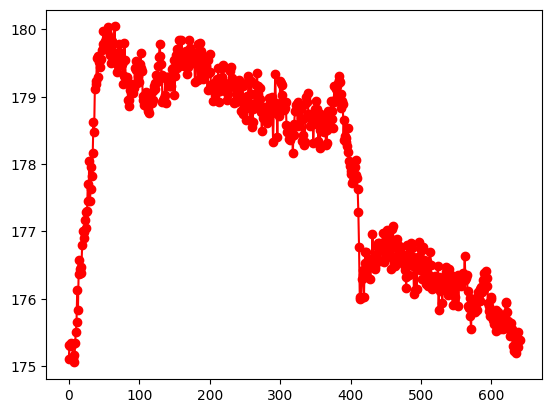

In [222]:
import matplotlib.pyplot as plt
plt.plot(r_vector, linestyle='-', marker='o', color='r')

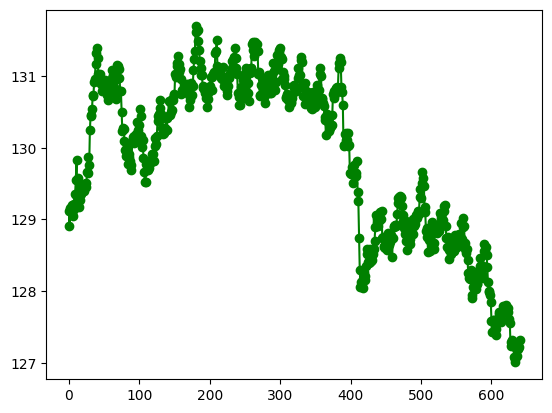

In [223]:
import matplotlib.pyplot as plt
plt.plot(g_vector, linestyle='-', marker='o', color='g')

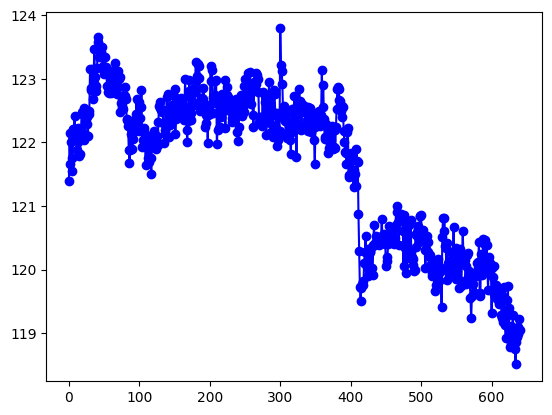

In [224]:
import matplotlib.pyplot as plt
plt.plot(b_vector, linestyle='-', marker='o', color='b')

# código final limpo para as bochechas

In [225]:
'''
input any video of a person in .mp4 and choose the rgb channel you want to extract
output is the mean of each frame of the rgb channel after masking only the cheeks of the person
'''

import os
import urllib.request
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

def download_model_if_missing(model_path="face_landmarker.task"):
    model_url = "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task"
    if not os.path.exists(model_path):
        print("Downloading face_landmarker.task model...")
        urllib.request.urlretrieve(model_url, model_path)
        print("Download complete!")

def extract_upper_cheeks_rgb(video_path: str, model_path: str = "face_landmarker.task"):
    """
    Tracks upper cheek masks (left + right) and calculates average R, G, and B channel
    values for each frame across the combined cheek regions.

    Returns: r_means, g_means, b_means: 1D numpy arrays containing mean values per frame.
    """

    #run model on video for 1 face
    download_model_if_missing(model_path)
    base_options = python.BaseOptions(model_asset_path=model_path)
    options = vision.FaceLandmarkerOptions(base_options=base_options,running_mode=vision.RunningMode.VIDEO, num_faces=1)
    detector = vision.FaceLandmarker.create_from_options(options)

    #upper cheek landmarks
    LEFT_UPPER_CHEEK = [117, 118, 101, 36, 205, 207, 187, 147, 123]
    RIGHT_UPPER_CHEEK = [346, 347, 330, 266, 425, 427, 411, 376, 352]

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print(f"Error: Could not open video {video_path}")
        return None, None, None

    #get information about the video file
    fps = int(cap.get(cv2.CAP_PROP_FPS)) or 30
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    frame_timestamp_ms = 0
    frame_duration_ms = int(1000 / fps)

    # Buffers for temporal smoothing
    prev_left_pts = None
    prev_right_pts = None
    smooth_factor = 0.6

    # Output vectors
    r_means, g_means, b_means = [], [], []


    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb_frame)

        detection_result = detector.detect_for_video(mp_image, frame_timestamp_ms)
        frame_timestamp_ms += frame_duration_ms

        if detection_result.face_landmarks:
            landmarks = detection_result.face_landmarks[0]

            def get_raw_pts(landmark_indices):
                pts = []
                for idx in landmark_indices:
                    lm = landmarks[idx]
                    pts.append([int(lm.x * width), int(lm.y * height)])
                return np.array(pts, dtype=np.float32)

            # Extract raw points of the cheeks
            raw_left_pts = get_raw_pts(LEFT_UPPER_CHEEK)
            raw_right_pts = get_raw_pts(RIGHT_UPPER_CHEEK)

            # Temporal Smoothing (to prevent glitches when the face moves)
            if prev_left_pts is None:
                smooth_left_pts = raw_left_pts
            else:
                #exponntial moving average: position of the point is based on the position of the current frame and the previous frame
                #smooth factor can be adjusted: currently it's 0.6
                smooth_left_pts = (smooth_factor * raw_left_pts) + ((1 - smooth_factor) * prev_left_pts)
            prev_left_pts = smooth_left_pts

            if prev_right_pts is None:
                smooth_right_pts = raw_right_pts
            else:
                smooth_right_pts = (smooth_factor * raw_right_pts) + ((1 - smooth_factor) * prev_right_pts)
            prev_right_pts = smooth_right_pts

            #convert to integer pixel coordinates
            left_int = smooth_left_pts.astype(np.int32)
            right_int = smooth_right_pts.astype(np.int32)

            #convex hulls to guarantee non-intersecting shapes
            left_hull = cv2.convexHull(left_int)
            right_hull = cv2.convexHull(right_int)

            # Create binary mask for both cheeks (255 inside cheeks, 0 outside)
            cheeks_mask = np.zeros((height, width), dtype=np.uint8)
            cv2.fillPoly(cheeks_mask, [left_hull], 255)
            cv2.fillPoly(cheeks_mask, [right_hull], 255)

            # Calculate mean BGR values strictly within the cheek regions
            # OpenCV frames are BGR by default, we need to convert to RGB
            b_mean, g_mean, r_mean, _ = cv2.mean(frame, mask=cheeks_mask)

            r_means.append(r_mean)
            g_means.append(g_mean)
            b_means.append(b_mean)
        else:
            # If no face is detected, append 0
            r_means.append(0)
            g_means.append(0)
            b_means.append(0)

    cap.release()
    detector.close()

    print(f"Extraction complete! Extracted {len(r_means)} frame measurements.")
    return np.array(r_means), np.array(g_means), np.array(b_means), fps


def signal_extraction_main_cheeks(input_video, input_channel):
  '''
  input_video is a video file .mp4
  input_chanel is either:
  'r' for red channel,'g' for green channel or 'b' for blue channel
  '''

  # Run signal extraction
  r_vector, g_vector, b_vector, fps = extract_upper_cheeks_rgb(input_video)
  if input_channel == 'r':
      return r_vector, fps
  elif input_channel == 'g':
      return g_vector, fps
  elif input_channel == 'b':
      return b_vector, fps
  else:
      print('invalid input channel')



# Extracting HR with FFT - Testing

In [226]:
import scipy
import numpy as np

In [254]:
#exemplo de utilização
import matplotlib.pyplot as plt
green_forehead, fps = signal_extraction_main_forehead('/content/input_person.mp4', 'g')
green_cheeks, fps = signal_extraction_main_cheeks('/content/input_person.mp4', 'g')

Extraction complete! Extracted 674 frame measurements.
Extraction complete! Extracted 674 frame measurements.


In [255]:
time = [i/fps for i in range(len(green_forehead))]

Text(0, 0.5, 'Channel intensity')

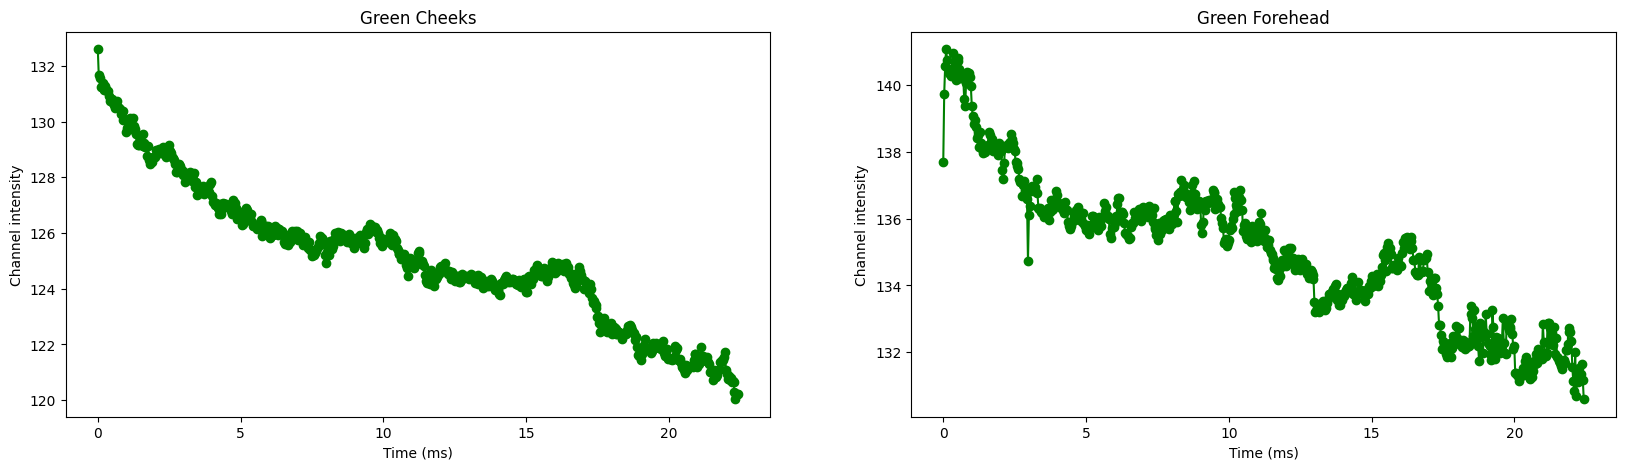

In [256]:
# Cheeks
plt.figure(figsize=(20,5))
plt.subplot(1,2,1)
plt.plot(time, green_cheeks, linestyle='-', marker='o', color="green")
plt.title("Green Cheeks")
plt.xlabel("Time (ms)")
plt.ylabel("Channel intensity")

# Forehead
plt.subplot(1,2,2)
plt.plot(time, green_forehead, linestyle='-', marker='o', color="green")
plt.title("Green Forehead")
plt.xlabel("Time (ms)")
plt.ylabel("Channel intensity")

In [287]:
original_signal = green_cheeks

In [288]:
def ffourier_transform(signal, fps):
  fourier = scipy.fft.fft(signal)
  freq_array = scipy.fft.fftfreq(len(signal), 1.0/fps)

  return fourier, freq_array

(0.0, 100.0)

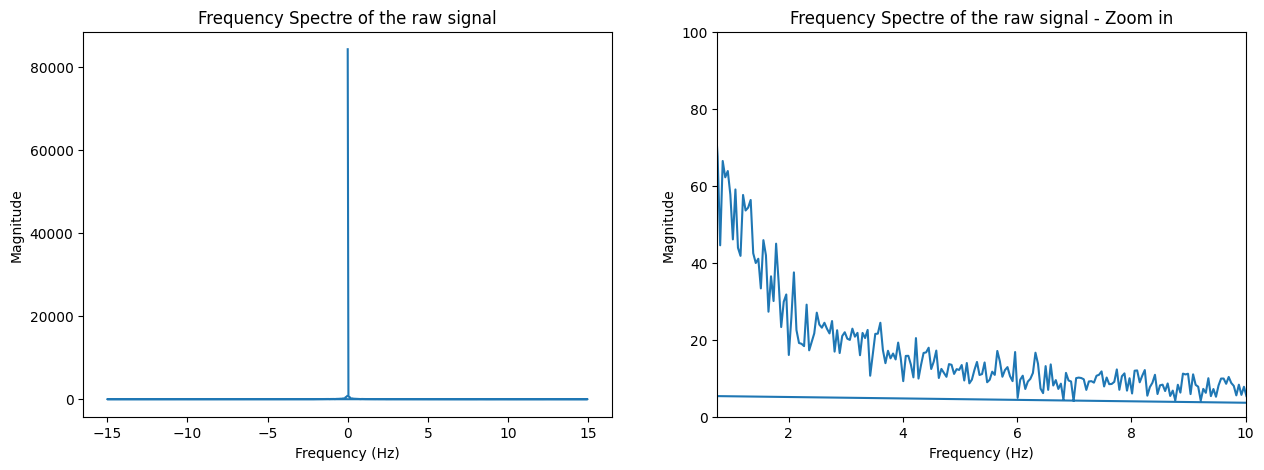

In [289]:
# Fast Fourier Transform - no filtering
fourier, freq_array = ffourier_transform(original_signal, fps)

plt.figure(figsize=(15,5))

plt.subplot(1,2,1)
plt.plot(freq_array, np.abs(fourier))
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.title('Frequency Spectre of the raw signal')

plt.subplot(1,2,2)
plt.plot(freq_array, np.abs(fourier))
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.title("Frequency Spectre of the raw signal - Zoom in")
plt.xlim(0.75, 10.0)
plt.ylim(0, 100)

In [290]:
def filtering(fc, N, fps, signal):
  fc_lower, fc_upper = fc
  # Filter definition
  coef = scipy.signal.butter(N, [fc_lower, fc_upper], btype='bandpass', fs=fps, output="sos")
  #Filter result
  filtered_signal = scipy.signal.sosfiltfilt(coef, signal)

  return filtered_signal

In [291]:
# Band pass filter
fc_upper = 5 #Hz = 300 bpm
fc_lower = 0.6 #Hz = 35 bpm
N = 3
fps=30

filtered_signal = filtering([fc_lower, fc_upper], N, fps, original_signal)


Text(0, 0.5, 'Channel intensity')

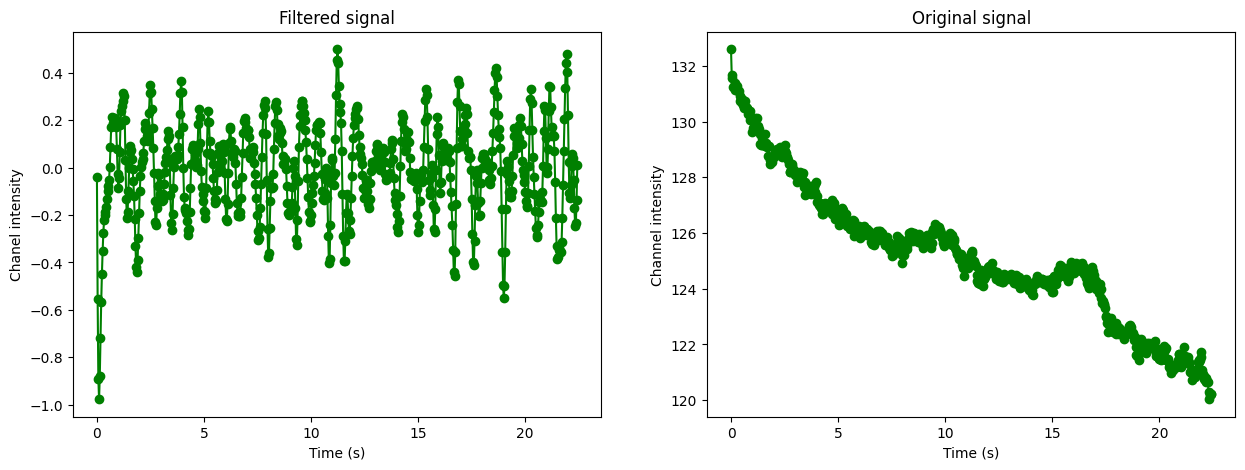

In [292]:
plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
plt.plot(time, filtered_signal, linestyle='-', marker='o', color="green")
plt.title("Filtered signal")
plt.xlabel("Time (s)")
plt.ylabel("Chanel intensity")

plt.subplot(1,2,2)
plt.plot(time,original_signal, linestyle='-', marker='o', color="green")
plt.title("Original signal")
plt.xlabel("Time (s)")
plt.ylabel("Channel intensity")

(0.5, 10.0)

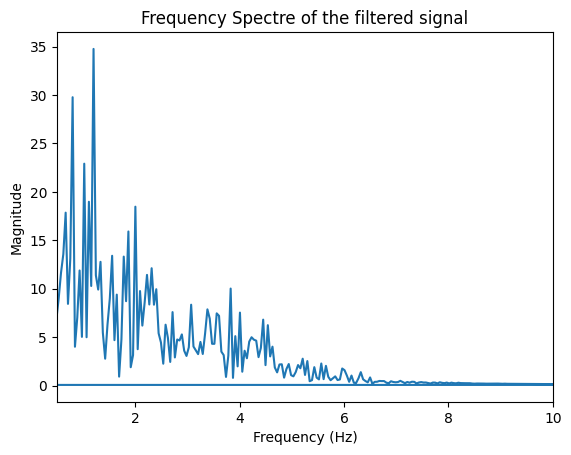

In [293]:
fourier, freq_array = ffourier_transform(filtered_signal, 30)

plt.plot(freq_array, np.abs(fourier), linestyle='-')
plt.title("Frequency Spectre of the filtered signal")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0.5, 10)

In [294]:
gt = 70.5

In [295]:
idx = np.abs(fourier).argmax()
hr = (freq_array[idx])*60
error = ((hr-gt)/gt)*100

print(f"HR: {round(hr, 2)} bpm ({round(hr/60,2)} Hz)")
print(f"Error: {round(error,2)} %")

HR: 72.11 bpm (1.2 Hz)
Error: 2.28 %


In [296]:
1.29*60

77.4

# Extracting Heart Rate

In [306]:
# Band Pass filter to reduce noise and extrac target frequencies
def band_pass_butter_filtering(signal, fps, fc, N):
  fc_lower, fc_upper = fc
  # Filter definition
  coef = scipy.signal.butter(N, [fc_lower, fc_upper], btype='bandpass', fs=fps, output="sos")
  #Filter result
  filtered_signal = scipy.signal.sosfiltfilt(coef, signal)

  return filtered_signal

# Fourier Transform to get the most relevant frequencies of the signal
def ffourier_transform(signal, fps):
  # Applies Fourier Transform to the signal
  fourier = scipy.fft.fft(signal)
  # Gets indexes of the signal and converts them into timestamps for each value of FFT
  freq_array = scipy.fft.fftfreq(len(signal), 1.0/fps)

  return fourier, freq_array

# Returns value of heart rate for a computed Fourier transform
def get_hr_bpm(fourier, freq_array):
  idx = np.abs(fourier).argmax()
  hr = freq_array[idx]*60
  return hr

"""
KEY INPUTS:
   - Raw signal
   - The filter: cut-off frequency (fc=[fc_lower, fc_upper]), order (N), fps (get from video)

Inputs for testing:
   - Ground Truth

OUTPUT:
   - Heart Rate
"""

'\nKEY INPUTS:\n   - Raw signal\n   - The filter: cut-off frequency (fc=[fc_lower, fc_upper]), order (N), fps (get from video)\n\nInputs for testing:\n   - Ground Truth\n\nOUTPUT:\n   - Heart Rate\n'

In [307]:
def extract_hr(raw_signal, fps=30, fc=[0.6, 5], N=3):
  filtered = band_pass_butter_filtering(raw_signal, fps, fc, N)
  fourier, freq_array = ffourier_transform(filtered, fps)
  heart_rate = get_hr_bpm(fourier, freq_array)

  return heart_rate

In [319]:
hr_cheeks = extract_hr(green_cheeks)
hr_forehead = extract_hr(green_forehead)

gt = 70.5
error_cheeks = (hr_cheeks-gt)/gt*100
error_forehead = (hr_forehead-gt)/gt*100

print(f"Ground Truth: {gt} bpm")
print(f"Heart Rate (Cheeks): {round(hr_cheeks,2)} bpm")
print(f"Error: {round(error_cheeks,2)}%")
print(f"Heart Rate (Forehead): {round(hr_forehead,2)} bpm")
print(f"Error: {round(error_forehead,2)}%")

Ground Truth: 70.5 bpm
Heart Rate (Cheeks): 72.11 bpm
Error: 2.28%
Heart Rate (Forehead): 77.45 bpm
Error: 9.86%
